# 10. More strategies on the frozen embeddings (added 6/11)

**Question.** Starting from the same frozen vectors (Qwen3-Embedding-8B, Mistral-Small-24B), can another regressor or
another way of training predict the NewsGuard score better than the ridge of step 7? TF-IDF stays as it is (step 7) and
is the reference; ModernBERT is not touched.

**Fixed before the results** (details in `boost.py`):
- same outlets, same 5 outer folds, same 3 inner folds and inner criterion (Spearman per outlet) as step 7;
- representations: Qwen3-8B, Mistral-24B layer 27 (step 7), layer 40, Qwen ⊕ Mistral, Mistral 27 ⊕ 40;
- methods: ridge (step 7), ridge with every outlet counting the same, with rare scores counting more (LDS), on the
  score quantile; ridge, mixup and RBF kernel ridge on the outlet (mean vector and random bags of articles); RBF kernel
  ridge and a small neural network on the articles; attention over the articles of an outlet (multiple-instance);
  then the mean of Qwen and Mistral and «auto» (the method with the best inner score, fold by fold);
- every setting chosen on the inner folds only; the stretched score uses the training scores only; every outlet is
  predicted from all its articles and from k random articles (20 draws, the same for all, TF-IDF included);
- paired bootstrap over outlets (1,000, seed 7) against TF-IDF and against the ridge of step 7.

**Honest reading.** Many rows are compared: the best row of a table is optimistic. The numbers to quote are those of
«auto», which choose the method without looking at the test outlets.

Run on the server: `run_boost.sh` (one process per representation and method, with a time limit). This notebook only
reads the saved predictions.

In [1]:
import warnings

import numpy as np
import pandas as pd

import common as C

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)
C.OUT.mkdir(parents=True, exist_ok=True)
LOG = C.OUT / "log.txt"
print(C.environment())
import matplotlib.pyplot as plt

import boost as BO
import boost_eval as BE

art, outlets, rows = BO.load()

{'python': '3.12.3', 'seed': 42, 'split seed': 1, 'numpy': '2.5.4', 'pandas': '3.0.6', 'sklearn': '1.9.1', 'scipy': '1.18.1', 'torch': '2.5.1+cu121', 'transformers': '4.51.3', 'bitsandbytes': '0.50.2', 'trafilatura': '2.3.1'}


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


## What has been computed

In [2]:
done = BO.collect().groupby(["embedding", "method"]).domain.nunique().unstack()
print("outlets predicted (226 = all 5 folds):"); display(done.reindex(columns=BO.METHODS))
err = BO.OUT / "errors.txt"
print(open(err).read()[-3000:] if err.exists() else "no errors")

outlets predicted (226 = all 5 folds):


method,ridge,ridge_outlet,ridge_lds,ridge_median,ridge_quantile,outlet_mean,outlet_bags,outlet_mixup,outlet_krr,outlet_knn,krr,mlp,mil,mil_rank
embedding,,,,,,,,,,,,,,
Mistral-24B,226,226,226,226,226,226,226,226,226,226,226,226,226,226
Mistral-24B-L27+L40,226,226,226,226,226,226,226,226,226,226,226,226,226,226
Mistral-24B-L40,226,226,226,226,226,226,226,226,226,226,226,226,226,226
Qwen+Mistral,226,226,226,226,226,226,226,226,226,226,226,226,226,226
Qwen3-8B,226,226,226,226,226,226,226,226,226,226,226,226,226,226


no errors


## Settings chosen on the inner folds (best inner Spearman, mean over the 5 outer folds)

In [3]:
inner = BE.inner_choices()
inner.pivot_table(index="method", columns="embedding", values="inner Spearman").reindex(BO.METHODS).round(3)

embedding,Mistral-24B,Mistral-24B-L27+L40,Mistral-24B-L40,Qwen+Mistral,Qwen3-8B
method,,,,,
ridge,0.720,0.712,0.699,0.712,0.692
ridge_outlet,0.723,0.722,0.711,0.719,0.702
ridge_lds,0.717,0.720,0.708,0.716,0.697
ridge_median,0.720,0.720,0.712,0.714,0.699
ridge_quantile,0.728,0.726,0.716,0.723,0.696
outlet_mean,0.713,0.700,0.674,0.705,0.636
outlet_bags,0.716,0.713,0.699,0.706,0.659
outlet_mixup,0.717,0.715,0.700,0.711,0.665
outlet_krr,0.703,0.700,0.687,0.699,0.664


In [4]:
inner.sort_values(["embedding", "method", "fold"])[["embedding", "method", "fold", "inner Spearman", "chosen"]]

,embedding,method,fold,inner Spearman,chosen
197,Mistral-24B,krr,1,0.748289,"{'weights': 'outlet', 'gamma': 0.25, 'alpha': 10.0}"
196,Mistral-24B,krr,2,0.708059,"{'weights': 'outlet', 'gamma': 0.5, 'alpha': 10.0}"
195,Mistral-24B,krr,3,0.694746,"{'weights': 'outlet', 'gamma': 0.5, 'alpha': 10.0}"
198,Mistral-24B,krr,4,0.723348,"{'weights': 'none', 'gamma': 1.0, 'alpha': 1.0}"
199,Mistral-24B,krr,5,0.755202,"{'weights': 'lds', 'gamma': 0.5, 'alpha': 0.1}"
...,...,...,...,...,...
122,Qwen3-8B,ridge_quantile,1,0.710643,"{'weights': 'outlet', 'target': 'quantile', 'alpha': 10000.0}"
121,Qwen3-8B,ridge_quantile,2,0.647387,"{'weights': 'outlet', 'target': 'quantile', 'alpha': 10000.0}"
120,Qwen3-8B,ridge_quantile,3,0.653990,"{'weights': 'outlet', 'target': 'quantile', 'alpha': 100.0}"
123,Qwen3-8B,ridge_quantile,4,0.703904,"{'weights': 'outlet', 'target': 'quantile', 'alpha': 1000.0}"


## Results

In [5]:
S = BE.sources(outlets, art, rows)
R = BE.evaluate(S, outlets)
R.to_csv(BO.OUT / "results.csv", index=False)
print(S.source.nunique(), "sources")

96 sources


In [6]:
def table(k="all", score="stretched"):
    """✓ = significantly better than TF-IDF; ▲ = significantly better than the ridge of step 7 (same representation;
    Mistral-24B for the averages and auto)."""
    d = R[(R.k == k) & (R.score == score)].copy()
    d["text"] = [f"{v:.3f}" if m in ("Spearman", "Kendall") else f"{v:.1f}" for v, m in zip(d.value, d.measure)]
    d["text"] += np.where(d.get("beats TF-IDF", False) == True, " ✓", "") + np.where(d.get("beats ridge", False) == True, " ▲", "")
    t = d.pivot_table(index="source", columns="measure", values="text", aggfunc="first")[BE.MEASURES]
    order = d[d.measure == "Spearman"].set_index("source").value.sort_values(ascending=False).index
    return t.reindex(order)

### All articles, stretched score

In [7]:
table("all", "stretched")

measure,Spearman,Kendall,MAE,within 20
source,,,,
Qwen+Mistral · mlp,0.751 ✓ ▲,0.573 ✓ ▲,14.6 ✓,75.7
Mistral-24B · mlp,0.749 ✓,0.575 ✓,14.2 ✓,74.8
auto · Qwen+Mistral,0.745 ✓,0.569 ✓,14.9,72.6
auto · all,0.743 ✓,0.572 ✓,14.6 ✓,76.5
Qwen+Mistral · mil_rank,0.741,0.567 ✓,14.6 ✓,75.7
...,...,...,...,...
Qwen+Mistral · outlet_knn,0.614,0.451,18.3,62.8
Qwen+Mistral avg · outlet_knn,0.593,0.436,18.2,63.7
Mistral-24B-L27+L40 · outlet_knn,0.572,0.418,19.3,59.3


### All articles, predicted score (not stretched)

In [8]:
table("all", "normal")

measure,Spearman,Kendall,MAE,within 20
source,,,,
Qwen+Mistral · mlp,0.752 ✓ ▲,0.563 ✓ ▲,14.9 ✓ ▲,72.1 ✓
Mistral-24B · mlp,0.751 ✓,0.563 ✓,14.8 ✓ ▲,73.9 ✓ ▲
Qwen+Mistral avg · mlp,0.748 ✓,0.556 ✓,15.5 ✓,69.5 ✓
Mistral-24B-L27+L40 · ridge_quantile,0.746 ✓,0.575 ✓ ▲,15.4 ✓,74.3 ✓
Mistral-24B · ridge_quantile,0.745 ✓,0.568 ✓ ▲,15.4 ✓,74.8 ✓ ▲
...,...,...,...,...
Qwen+Mistral · outlet_knn,0.592,0.418,17.6,64.2
Qwen+Mistral avg · outlet_knn,0.575,0.404,17.9,63.7
Mistral-24B-L27+L40 · outlet_knn,0.548,0.387,17.4,62.8


### 5 articles per outlet, stretched score

In [9]:
table("5", "stretched")

measure,Spearman,Kendall,MAE,within 20
source,,,,
Mistral-24B · mlp,0.721 ✓,0.546 ✓,15.2 ✓,73.3 ✓
Qwen+Mistral · mlp,0.721 ✓,0.544 ✓,15.5 ✓,73.2 ✓
Qwen+Mistral avg · mlp,0.716 ✓,0.539 ✓,15.5 ✓,72.9 ✓
avg methods · Mistral-24B,0.714 ✓,0.538 ✓,15.8 ✓,72.2 ✓
Mistral-24B-L27+L40 · ridge_quantile,0.714 ✓,0.538 ✓,16.0 ✓,72.1 ✓
...,...,...,...,...
Qwen+Mistral · outlet_knn,0.568,0.414,19.4,62.9
Qwen+Mistral avg · outlet_knn,0.547,0.398,19.7,63.0
Mistral-24B-L27+L40 · outlet_knn,0.544,0.392,20.1,61.3


### 1 article per outlet, stretched score

In [10]:
table("1", "stretched")

measure,Spearman,Kendall,MAE,within 20
source,,,,
Mistral-24B-L27+L40 · ridge_quantile,0.632 ✓,0.468 ✓,17.9 ✓,67.7 ✓ ▲
Mistral-24B · ridge_quantile,0.631 ✓,0.466 ✓,18.0 ✓,67.4 ✓
Qwen+Mistral · mlp,0.631 ✓,0.464 ✓,17.9 ✓,66.3 ✓
Qwen+Mistral avg · mlp,0.631 ✓,0.465 ✓,17.9 ✓,66.9 ✓
Mistral-24B · ridge_outlet,0.629 ✓,0.461 ✓,18.1 ✓,67.1 ✓
...,...,...,...,...
Qwen3-8B · outlet_krr,0.424,0.304,22.4,57.7
Qwen3-8B · outlet_mean,0.421,0.302,22.5,57.2
TF-IDF,0.420,0.301,22.4,57.2


## Every source with all articles (stretched)

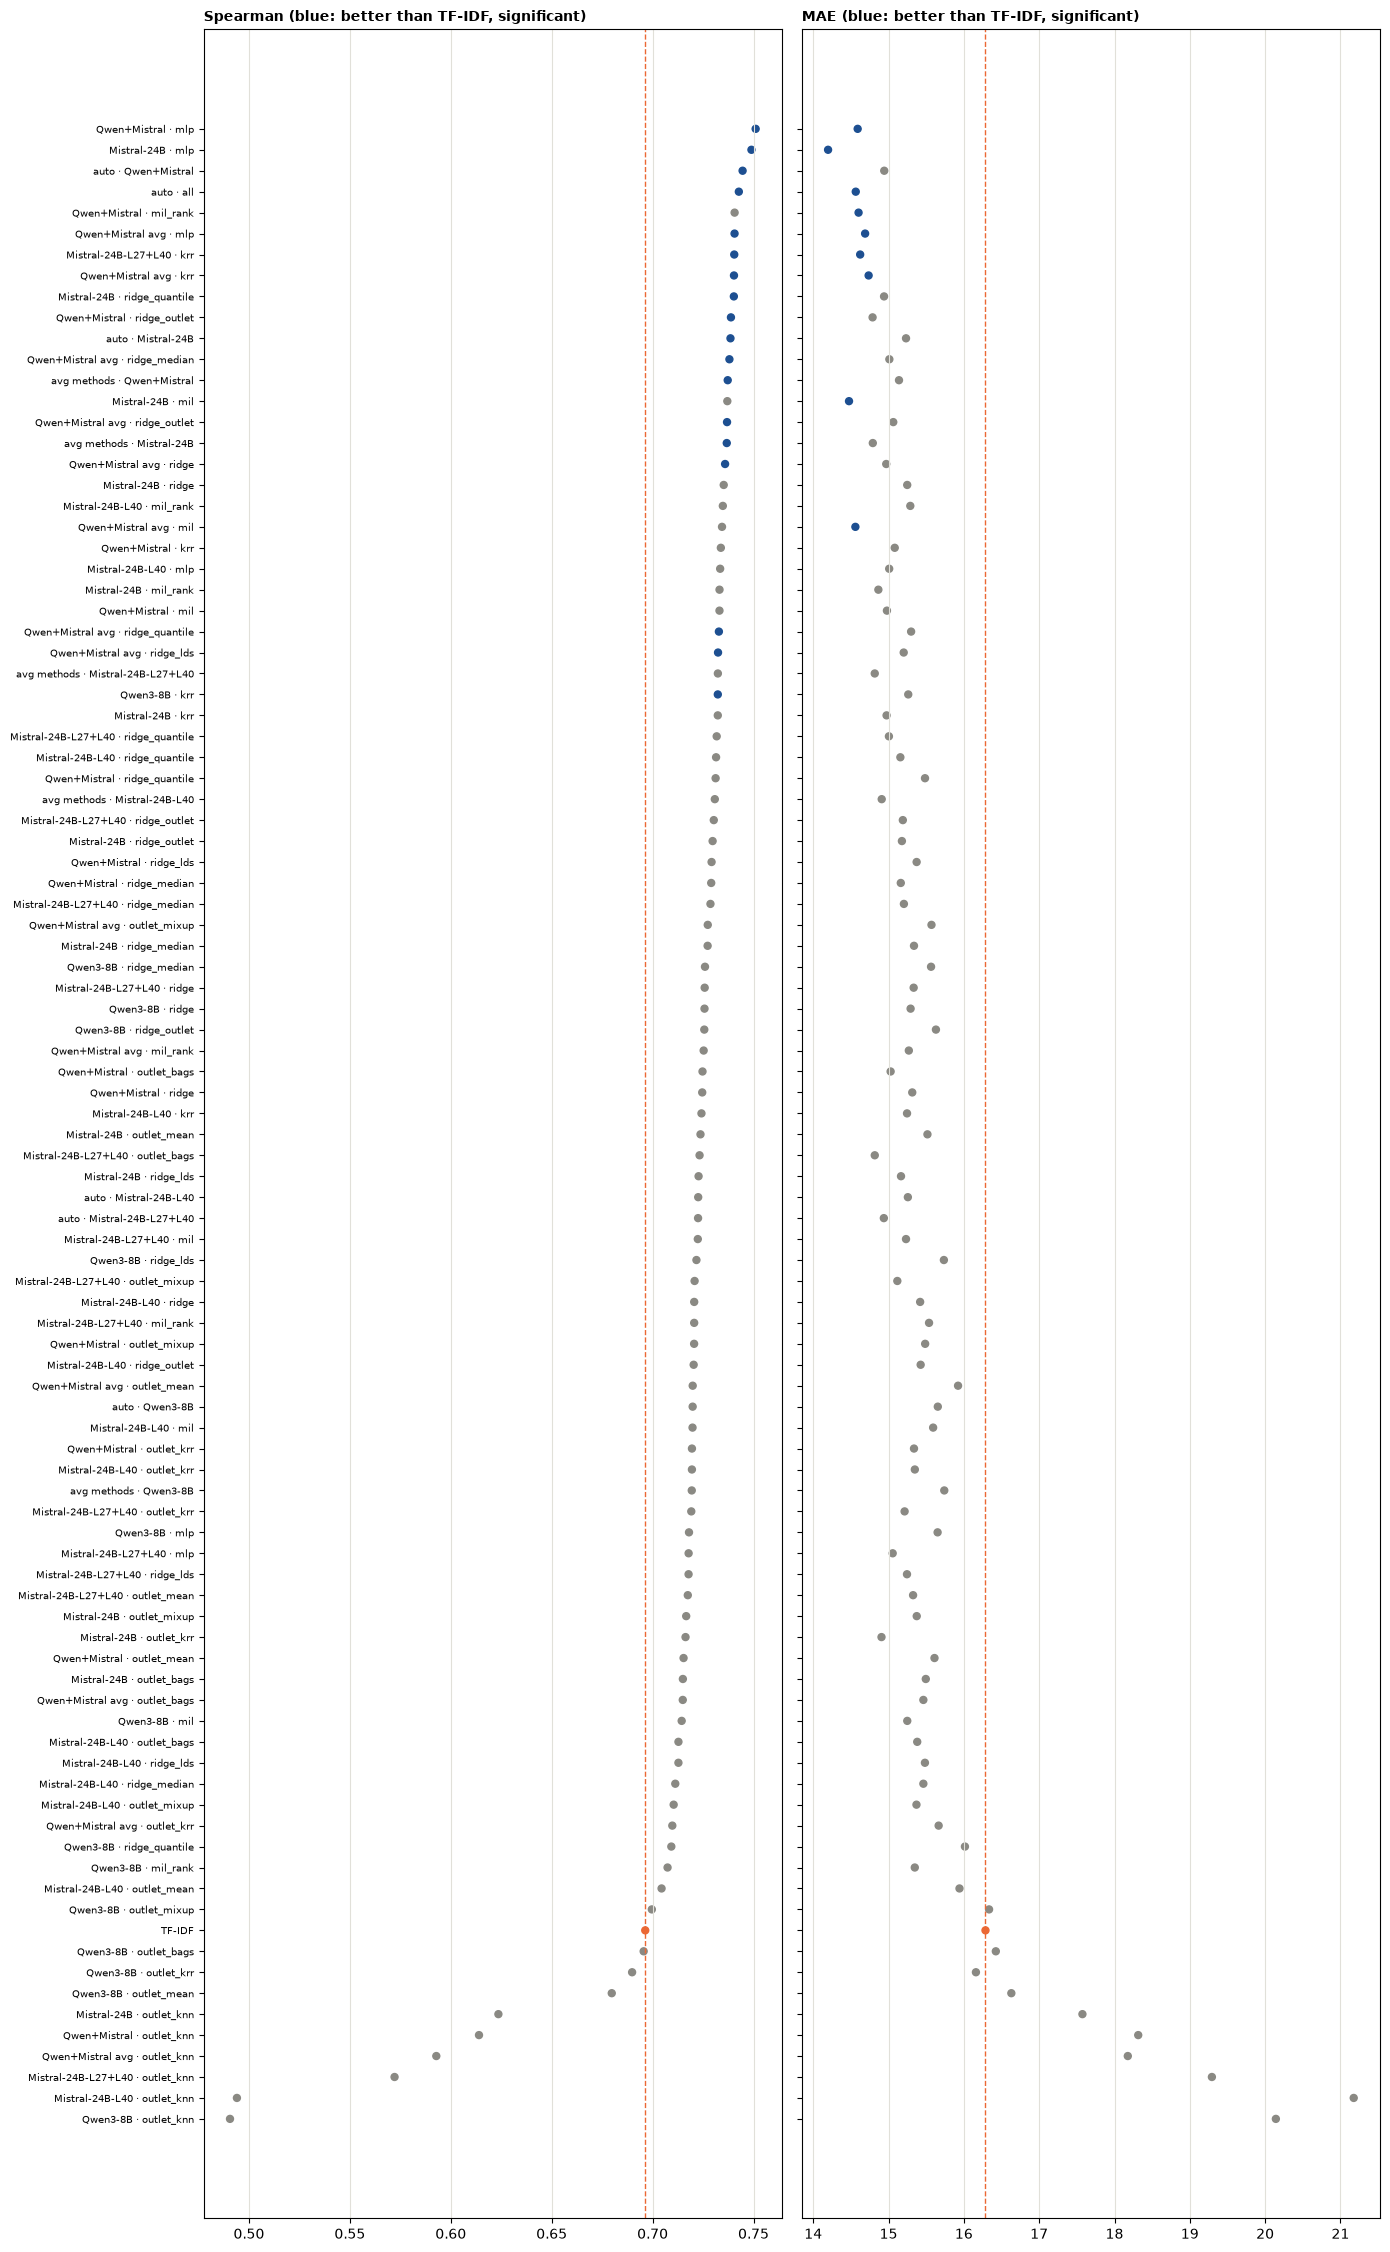

In [11]:
d = R[(R.k == "all") & (R.score == "stretched")]
fig, axes = plt.subplots(1, 2, figsize=(14, 0.22 * d.source.nunique() + 1.5), sharey=True)
order = d[d.measure == "Spearman"].set_index("source").value.sort_values().index
for ax, m in zip(axes, ["Spearman", "MAE"]):
    x = d[d.measure == m].set_index("source").reindex(order)
    colour = np.where(x["beats TF-IDF"] == True, "#1d4f91", np.where(x.index == "TF-IDF", "#eb6834", "#8a8983"))
    ax.scatter(x.value, range(len(x)), c=colour, s=25)
    tf = x.loc["TF-IDF", "value"]; ax.axvline(tf, color="#eb6834", lw=1, ls="--")
    ax.set_title(f"{m} (blue: better than TF-IDF, significant)", loc="left", fontsize=10, fontweight="bold")
    ax.grid(axis="x", color="#e1e0d9")
axes[0].set_yticks(range(len(order)), order, fontsize=7)
plt.tight_layout(); plt.savefig(BO.OUT / "all_sources.png", dpi=150, bbox_inches="tight"); plt.show()

## Curves: TF-IDF, the ridge of step 7, auto and the three methods with the best inner score

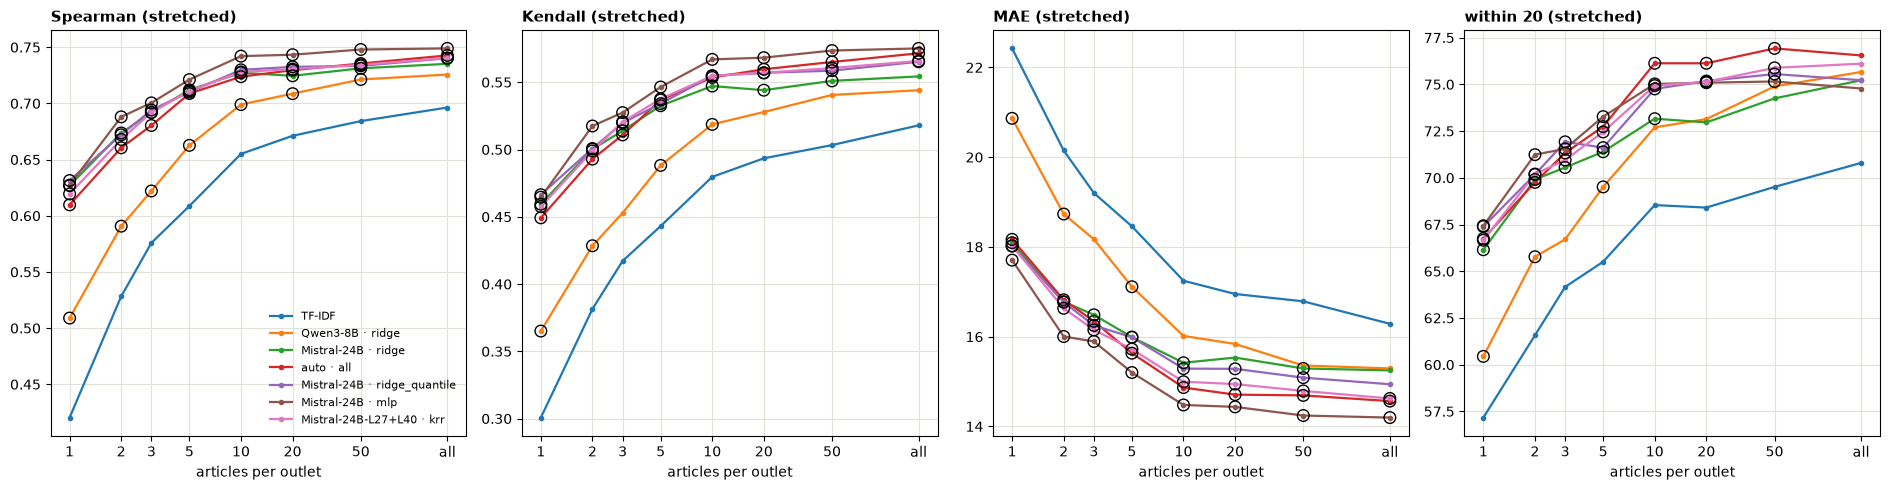

In [12]:
top = inner.groupby(["embedding", "method"])["inner Spearman"].mean().sort_values(ascending=False).head(3)
show = ["TF-IDF", "Qwen3-8B · ridge", "Mistral-24B · ridge", "auto · all"] + [f"{e} · {m}" for e, m in top.index]
X = [1, 2, 3, 5, 10, 20, 50, 160]
fig, axes = plt.subplots(1, 4, figsize=(19, 5))
for ax, m in zip(axes, BE.MEASURES):
    for s in show:
        d = R[(R.source == s) & (R.score == "stretched") & (R.measure == m)].set_index("k").reindex([str(k) for k in BO.K])
        if d.value.isna().all():
            continue
        ax.plot(X, d.value, "o-", ms=3, lw=1.6, label=s)
        win = d["beats TF-IDF"].fillna(False).to_numpy(bool)
        ax.scatter(np.array(X)[win], d.value.to_numpy()[win], s=70, facecolor="none", edgecolor="k", zorder=4)
    ax.set_xscale("log"); ax.set_xticks(X, [str(k) for k in BO.K]); ax.minorticks_off()
    ax.set_title(f"{m} (stretched)", loc="left", fontsize=11, fontweight="bold"); ax.set_xlabel("articles per outlet")
    ax.grid(color="#e1e0d9")
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(BO.OUT / "curves.png", dpi=150, bbox_inches="tight"); plt.show()

## In short

In [13]:
for k in ["all", "5", "1"]:
    for score in ["stretched", "normal"]:
        d = R[(R.k == k) & (R.score == score)]
        line = []
        for s in ["TF-IDF", "Mistral-24B · ridge", "auto · Mistral-24B", "auto · all"]:
            x = d[d.source == s].set_index("measure").value
            if len(x):
                line.append(f"{s}: ρ {x['Spearman']:.3f}, MAE {x['MAE']:.1f}")
        print(f"k={k:>3}, {score:9}  " + " | ".join(line))
print()
for name in ["TF-IDF", "ridge"]:
    col = f"beats {name}"
    n = R[(R.k == "all") & (R[col] == True)].groupby(["score", "measure"]).size()
    print(f"sources significantly better than {name} with all articles:"); print(n.to_string(), "\n")

k=all, stretched  TF-IDF: ρ 0.696, MAE 16.3 | Mistral-24B · ridge: ρ 0.735, MAE 15.2 | auto · Mistral-24B: ρ 0.739, MAE 15.2 | auto · all: ρ 0.743, MAE 14.6
k=all, normal     TF-IDF: ρ 0.691, MAE 17.7 | Mistral-24B · ridge: ρ 0.735, MAE 15.7 | auto · Mistral-24B: ρ 0.731, MAE 15.1 | auto · all: ρ 0.724, MAE 15.2
k=  5, stretched  TF-IDF: ρ 0.609, MAE 18.5 | Mistral-24B · ridge: ρ 0.712, MAE 16.0 | auto · Mistral-24B: ρ 0.706, MAE 16.1 | auto · all: ρ 0.709, MAE 15.6
k=  5, normal     TF-IDF: ρ 0.611, MAE 18.1 | Mistral-24B · ridge: ρ 0.715, MAE 16.0 | auto · Mistral-24B: ρ 0.702, MAE 15.6 | auto · all: ρ 0.700, MAE 15.8
k=  1, stretched  TF-IDF: ρ 0.420, MAE 22.4 | Mistral-24B · ridge: ρ 0.627, MAE 18.1 | auto · Mistral-24B: ρ 0.605, MAE 18.4 | auto · all: ρ 0.610, MAE 18.2
k=  1, normal     TF-IDF: ρ 0.417, MAE 20.1 | Mistral-24B · ridge: ρ 0.629, MAE 17.1 | auto · Mistral-24B: ρ 0.596, MAE 17.3 | auto · all: ρ 0.603, MAE 17.4

sources significantly better than TF-IDF with all article